# CS781 Capstone · Phase 7
## Prior Case Retrieval

**Scope** · Prior-case retrieval with the Phase 1 legal backbones and the original 16k BPE vocabulary.

**Rerank** reuses a saved EMA checkpoint and adds evidence from the full case texts. The reranker learns from Train query–candidate labels. Dev compares dense retrieval, rank fusion and the learned reranker before the selected method exports seven cases per Test query.

**Train** fits or resumes the dense retriever. A shared document head pools up to four windows into one vector, and cosine similarity ranks candidates within their split.

**KD** trains the efficient student from its Phase 1 weights. It uses the encoder-decoder gold pipeline's ranking on Train, alongside the original gold relevance labels.

| Preset | Phase 1 adaptation | Experiment |
|---|---|---|
| `decoder` | Upper two blocks, final normalization and retrieval head | Partial fine-tuning |
| `encoder_decoder` | IA³ scales on key, value and feed-forward activations plus the head | Parameter-efficient adaptation |
| `prefix` | Rank-8 output-side LoRMA+ plus the head | Required LoRMA-family experiment |
| `efficient` | Fully trained compact model retaining original blocks 0, 7 and 15 | Gold-only student control |

The best larger checkpoints are retained for the subsequent distillation experiment. The gold student measures the compact architecture under the same gold supervision.

### Kaggle inputs

Mount the [prepared PCR bundle](phase7_preparation.ipynb) and the matching original Phase 1 checkpoint. Set `PREPARED_INPUT` and `PHASE1_CHECKPOINT` to the mounted paths as needed. Set `RECOVERY_INPUT` to the expanded dense run directory when resuming in a new session. Set `TEACHER_RERANK_DIR` to the [encoder-decoder reranking output](phase7_rerank_encoder_decoder.ipynb) containing `rerank_report.json` and `dense_cache/`. Continue to [efficient KD reranking](phase7_rerank_efficient_kd.ipynb) after training.


## 1. Kaggle configuration

Select **GPU T4 ×2**. Attach the Phase 7 prepared ZIP or expanded bundle, the selected original Phase 1 checkpoint and the official evaluator if available. Internet access can stay off.

For reranking, also attach **prep-2** with its original tokenizer and matching cache manifest. The default reads the saved efficient run from working storage. If the run is mounted from a previous session, set `BASE_RUN_DIR` to that directory. It needs `run_config.json` and either the published best checkpoint with its metadata or the matching metrics and best snapshot.

For KD, use `RUN_MODE = "kd"`, the original efficient checkpoint, the prepared data and **prep-2**. Point `TEACHER_RERANK_DIR` to the encoder-decoder gold rerank folder containing `rerank_report.json` and `dense_cache/`. The prior backup layout keeps the teacher's `runs/` and `reranked/` directories under one root. The earlier rerank report format also uses the saved encoder-decoder `run_config.json` to identify its score cache.

| `ARCHITECTURE` | Original Phase 1 checkpoint path suffix |
|---|---|
| `decoder` | `decoder_004_mixed217m/best_model.pt` |
| `encoder_decoder` | `encdec_002_mixed217m_stable/best_model.pt` |
| `prefix` | `prefix_001_mixed217m/best_model.pt` |
| `efficient` | `efficient_002_mixed217m_500m/best_model.pt` |

Match the architecture to your saved run or desired training preset. Fill an input path when the mounted inputs contain several matches.

In [1]:
from pathlib import Path

RUN_MODE = "kd"              # rerank | train | kd
ARCHITECTURE = "efficient"       # decoder | encoder_decoder | prefix | efficient
PREPARED_INPUT = None            # phase7_pcr_prepared_data.zip or expanded bundle folder
PHASE1_CHECKPOINT = None         # original best_model.pt, its containing folder, or its ZIP
EVALUATOR_INPUT = None           # evaluate_phase7.py
TOKENIZER_INPUT = None          # original prep-2 tokenizer_state.pkl with sibling manifest
BASE_RUN_DIR = None              # saved dense run for reranking, defaults to RUN_DIR
SHORTLIST_DEPTH = 80             # candidates per retrieval signal
TEACHER_RERANK_DIR = "/kaggle/input/datasets/ash9201kk/phase7-endec-teacher-backup/reranked/encoder_decoder_gold/68173e794806-k80"        # KD input directory containing rerank_report.json and dense_cache/
KD_WEIGHT = 0.5                  # weight of the teacher KL term

RECOVERY_INPUT = None            # mounted run directory for training recovery
RUN_NAME = "efficient_kd_encdec"                  # defaults to <architecture>_gold
EXPORT_ONLY = False              # export from an existing recovery checkpoint
CONTINUE_STOPPED = False         # explicitly reopen a run stopped by patience or manually
VERBOSE = False                  # show batch, encoding and checkpoint detail

MAX_EPOCHS = 50
MAX_RUN_HOURS = 5.0
RECOVERY_MINUTES = 15.0
TRAIN_OVERRIDES = {}             # e.g. {"head_lr": 5e-5, "patience_checks": 12}

KAGGLE_INPUT = Path("/kaggle/input")
PROJECT_ROOT = Path("/kaggle/working/cs781_phase7")

print(f"Phase 7 PCR · {ARCHITECTURE} · {RUN_MODE}", flush=True)
print(f"Input mount · {KAGGLE_INPUT}\nWorking directory · {PROJECT_ROOT}", flush=True)

Phase 7 PCR · efficient · kd
Input mount · /kaggle/input
Working directory · /kaggle/working/cs781_phase7


## 2. Self-contained project source

The cell below verifies and unpacks the pinned Phase 1 models, the PCR preparation components and the training source. It is collapsed to keep the notebook readable. The extracted `src/` contains the editable modules and `source_manifest.json` records their SHA-256 digests.

In [2]:
import base64
import hashlib
import io
import json
import sys
import zipfile

SOURCE_SHA256 = "cacd8a99aa968114bce7436006b0994998a1969b3dbc547d60b2542531121ed1"
SOURCE_PAYLOAD = """
...
"""

print("Verifying and unpacking the bundled project source", flush=True)
source_bytes = base64.b64decode(SOURCE_PAYLOAD)
if hashlib.sha256(source_bytes).hexdigest() != SOURCE_SHA256:
    raise RuntimeError("The embedded source checksum differs.")
SOURCE_DIR = PROJECT_ROOT / "code" / SOURCE_SHA256[:12]
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(source_bytes)) as archive:
    manifest = json.loads(archive.read("source_manifest.json"))
    for name, checksum in manifest.items():
        target = (SOURCE_DIR / name).resolve()
        if not target.is_relative_to(SOURCE_DIR.resolve()):
            raise ValueError("Unsafe embedded source path.")
        contents = archive.read(name)
        if hashlib.sha256(contents).hexdigest() != checksum:
            raise ValueError(f"Embedded source checksum differs for {name}.")
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(contents)
    (SOURCE_DIR / "source_manifest.json").write_text(json.dumps(manifest, indent=2))
sys.path.insert(0, str(SOURCE_DIR / "src"))
for name in manifest:
    if name.startswith("src/") and name.endswith(".py"):
        module = Path(name).stem
        loaded = getattr(sys.modules.get(module), "__file__", None)
        if loaded and Path(loaded).resolve() != (SOURCE_DIR / name).resolve():
            del sys.modules[module]
print(f"Source ready · {len(manifest)} verified files · {SOURCE_DIR}", flush=True)
del source_bytes, SOURCE_PAYLOAD

Verifying and unpacking the bundled project source
Source ready · 19 verified files · /kaggle/working/cs781_phase7/code/cacd8a99aa96


## 3. Run settings

Each optimizer update accumulates two batches of eight queries when both batches are full. Each query contributes one rotating positive, one BM25 hard negative and one random negative to a shared candidate pool. The listwise loss credits every known positive in that pool. Window length is 512 positions including special tokens, with overlap 64 and at most four windows spread over the case.

AdamW uses linear warmup over 5% of the planned updates and cosine decay. Training uses fp16 autocast with dynamic loss scaling on the T4s, gradient clipping and a trainable-parameter EMA with decay 0.98.

In [3]:
import re

print("Loading runtime and checking the accelerator", flush=True)
import pandas as pd
import torch
from IPython.display import display

from common import read_json
from pcr_train_data import RetrievalData
from pcr_train_io import evaluator_check, resolve_original, resolve_prepared
from pcr_training import TUNABLE_SETTINGS, Trainer, accelerator, initialize_model, settings_for

preparation = read_json(SOURCE_DIR / "preparation_defaults.json")
reference = read_json(SOURCE_DIR / "src" / "phase1_reference.json")
settings = settings_for(ARCHITECTURE, preparation, MAX_EPOCHS, MAX_RUN_HOURS, RECOVERY_MINUTES)
if RUN_MODE not in ("train", "rerank", "kd"):
    raise ValueError("RUN_MODE must be 'train', 'rerank' or 'kd'.")
if RUN_MODE == "kd" and ARCHITECTURE != "efficient":
    raise ValueError("The KD student uses ARCHITECTURE = 'efficient'.")
invalid = TRAIN_OVERRIDES.keys() - TUNABLE_SETTINGS
if invalid:
    raise ValueError(f"Unsupported TRAIN_OVERRIDES keys {sorted(invalid)}")
settings.update(TRAIN_OVERRIDES)
settings["verbose"] = VERBOSE
run_name = RUN_NAME or ("efficient_kd_encdec" if RUN_MODE == "kd" else f"{ARCHITECTURE}_gold")
if not re.fullmatch(r"[a-zA-Z0-9][a-zA-Z0-9_-]*", run_name):
    raise ValueError("RUN_NAME may contain letters, digits, underscores and hyphens.")
RUN_DIR = PROJECT_ROOT / "runs" / run_name
BASE_DIR = Path(BASE_RUN_DIR) if BASE_RUN_DIR else RUN_DIR
if RUN_MODE == "rerank":
    if not (BASE_DIR / "run_config.json").is_file():
        raise FileNotFoundError(f"Set BASE_RUN_DIR to a saved Phase 7 run. Expected {BASE_DIR / 'run_config.json'}")
    base_config = read_json(BASE_DIR / "run_config.json")
    if base_config["architecture"] != ARCHITECTURE:
        raise ValueError(f"Set ARCHITECTURE to {base_config['architecture']!r} for this run.")
    for key in ("geometry", "model_settings", "amp"):
        settings[key] = base_config["settings"][key]

device, devices = accelerator(require_two=True)
print(f"Run directory · {BASE_DIR if RUN_MODE == 'rerank' else RUN_DIR}", flush=True)

Loading runtime and checking the accelerator
GPU 0 · Tesla T4 · 14.6 GiB
GPU 1 · Tesla T4 · 14.6 GiB
Run directory · /kaggle/working/cs781_phase7/runs/efficient_kd_encdec


## 4. Prepared-data and scoring checks

The trainer verifies the packed tokens, official split-local IDs and BM25 files used in this run. Every gold link contributes to the metric denominator, including when a query has more than seven relevant cases. Queries with empty relevance sets contribute seven returned IDs to the Train denominator.

`Micro-F1@7 = 2 × hits / (7 × query count + gold link count)`

The code audits self-relevance in Train and Dev before choosing the same self-ID policy for training, BM25 and dense ranking. If both labelled splits have zero self-links, each query's own candidate ID is masked. The official evaluator, when attached, checks the Dev BM25 score using the matching candidate-ID file before training starts.

In [4]:
prepared, prepared_identity = resolve_prepared(KAGGLE_INPUT, PREPARED_INPUT, PROJECT_ROOT)
print("Opening the verified memory-mapped documents and auditing split IDs", flush=True)
data = RetrievalData(prepared, reference)
split_table = pd.DataFrame(data.audit).rename(columns={
    "split": "Split", "queries": "Queries", "candidates": "Candidates",
    "gold_links": "Gold links", "queries_with_gold": "Queries with gold",
    "shared_query_ids": "Self IDs in pool", "self_positives": "Gold self-links",
    "maximum_f1_at_7": "Maximum F1@7",
})
count_columns = ["Gold links", "Queries with gold", "Gold self-links"]
if VERBOSE:
    display(split_table.style.format({
        **{c: "{:,.0f}" for c in count_columns}, "Maximum F1@7": "{:.4f}"
    }, na_rep="—").hide(axis="index"))

bm25_table = pd.DataFrame([
    {"Split": name.title(), "Hits": score["hits"], "Micro-F1@7": score["micro_f1_at_7"],
     "Precision@7": score["micro_precision_at_7"], "Recall@7": score["micro_recall_at_7"]}
    for name, score in data.bm25_metrics.items()
])
if VERBOSE:
    display(bm25_table.style.format(precision=4).hide(axis="index").set_caption("BM25 reference"))
dev = data.splits["dev"]
preflight_dir = PROJECT_ROOT / "reranked" / "preflight" if RUN_MODE == "rerank" else RUN_DIR / "preflight"
score_check = evaluator_check(
    KAGGLE_INPUT, EVALUATOR_INPUT, preflight_dir,
    dev.truth, data.bm25_predictions["dev"], dev.candidate_ids, data.bm25_metrics["dev"],
)

Locating the packed Phase 7 preparation bundle
Prepared input · /kaggle/input/datasets/ash9201kk/phase7-dataset/phase7_pcr_prepared_data/phase7_pcr_prepared
Prepared file 1/12 · manifest.json
Prepared file 2/12 · index.json
Prepared file 3/12 · offsets.npy
Prepared file 4/12 · token_ids.bin | 0 / 496.0 MiB
Prepared file 4/12 · token_ids.bin | 496.0 MiB complete in 1.5s
Prepared file 5/12 · train_hard_negatives.json
Prepared file 6/12 · train_candidate_ids.json
Prepared file 7/12 · dev_candidate_ids.json
Prepared file 8/12 · test_candidate_ids.json
Prepared file 9/12 · train_bm25_top100.json
Prepared file 10/12 · dev_bm25_top100.json
Prepared file 11/12 · train_truth.json
Prepared file 12/12 · dev_truth.json
Opening the verified memory-mapped documents and auditing split IDs
Self IDs excluded per query · gold self-links Train 0, Dev 0
Official Dev score check · truth mapping · candidate IDs list
Official evaluator agrees · Dev BM25 Micro-F1@7 0.1012


## 5. Original weights and retrieval head

The checkpoint must match the selected Phase 1 run's SHA-256 and tokenizer signature. A strict load confirms the native architecture before adaptation. Every preset uses a bidirectional document GRU, attention over valid windows and an L2-normalized projection.

In [5]:
phase1 = reference["phase1_inputs"][ARCHITECTURE]
original_path = resolve_original(KAGGLE_INPUT, PHASE1_CHECKPOINT, PROJECT_ROOT, ARCHITECTURE, phase1)
model, runner, audit = initialize_model(settings, reference, original_path, device, devices)
display(pd.DataFrame([
    ("Original backbone", audit["original"]["original_parameters"]),
    ("Retrieval model total", audit["retrieval"]["total_parameters"]),
    ("Trainable backbone", audit["retrieval"]["backbone_trainable"]),
    ("Trainable retrieval head", audit["retrieval"]["head_trainable"]),
], columns=["Component", "Parameters"]).style.format({"Parameters": "{:,.0f}"}).hide(axis="index"))

Locating the original Phase 1 efficient checkpoint
Phase 1 input · /kaggle/input/datasets/ash9201kk/efficient-002/cs781_phase1/runs/efficient_002_mixed217m_500m/best_model.pt
Verifying Phase 1 checkpoint | 0 / 831.2 MiB
Verifying Phase 1 checkpoint | 831.2 MiB complete in 6.5s
Strict-loading original efficient weights and constructing the retrieval encoder
Model ready · Compact student · 55,068,544 trainable of 55,068,544 parameters


Component,Parameters
Original backbone,"217,872,384"
Retrieval model total,"55,068,544"
Trainable backbone,"54,164,736"
Trainable retrieval head,"903,808"


## 6. Select and export

The reranking pass builds a candidate union from dense, TF-IDF, BM25 and case-caption retrieval plus exact reported-citation matches. A small boosted-tree model uses the Train relevance labels to fit a relevance score for candidate pairs. The Dev shortlist oracle measures the highest score possible if every available relevant case were ranked first. Only the selected Dev method is used for the Test export. Dense wins a tie.

KD reconstructs the teacher's selected ranking method on Train. The student learns from gold relevance and a KL loss against rank-derived soft targets. A higher teacher rank gives a candidate more probability within each sampled batch. Some of the sampled hard negatives also come from the teacher's top-ranked non-gold cases. To apply the same reranking as the efficient gold control, rerun with `RUN_MODE = "rerank"` and `RUN_NAME = "efficient_kd_encdec"`.

In training mode, output defaults to one loss line per epoch and one result per paired F1 check. Set `VERBOSE = True` for batch and encoding detail. Eight consecutive checks without a new best stop training by default. Starting after 12 completed epochs, three consecutive Dev checks at least 0.02 below the best trigger an overfitting stop if the current Train F1 is at least 0.03 above Train F1 at that best check.

Recovery saves run at optimizer boundaries roughly every 15 active minutes and at a clean stop. The latest two committed states include EMA, optimizer, scaler, schedule, RNG state and the next batch. The run reserves time for a final paired check and Test export inside the five-hour active budget, which starts after input verification and model setup. It can finish earlier through the epoch cap or an early stop.

Resume in the same `RUN_NAME`. If Kaggle cleared working storage, mount a saved run and set `RECOVERY_INPUT` to its directory with `run_config.json`, `recovery/` and `best_snapshots/`. Epoch and time caps, learning rates, temperature, accumulation, evaluation frequency and patience may change. Keep the architecture, checkpoint, data, physical query batch size and document geometry consistent.

Extending a finished cosine schedule starts its next segment at a quarter of the configured peak rate. Increasing a reached epoch or time limit can reopen the run if there is sufficient budget. Set `CONTINUE_STOPPED = True` to reopen a patience stop or manual stop. A reopened run starts a new patience window and retains the prior best Dev score and checkpoint. Remove a previously created `STOP` marker before restarting.

In [6]:
if RUN_MODE == "rerank":
    from pcr_rerank import rerank_existing, resolve_text_tokenizer

    tokenizer = resolve_text_tokenizer(KAGGLE_INPUT, TOKENIZER_INPUT, PROJECT_ROOT, reference)
    rerank_report = rerank_existing(
        BASE_DIR, PROJECT_ROOT / "reranked", data, model, runner, settings, device,
        tokenizer, prepared_identity, phase1["sha256"], SOURCE_SHA256, SHORTLIST_DEPTH,
    )
    display(pd.DataFrame([
        {"Method": method, "Dev F1@7": metrics["micro_f1_at_7"], "Hits": metrics["hits"],
         "Selected": method == rerank_report["selected"]}
        for method, metrics in rerank_report["dev"].items()
    ]).style.format({"Dev F1@7": "{:.4f}"}).hide(axis="index"))
else:
    trainer_class, extra = Trainer, {}
    if RUN_MODE == "kd":
        from pcr_kd import DistillationTrainer, teacher_targets
        from pcr_rerank import resolve_text_tokenizer

        if not 0 < KD_WEIGHT < 1:
            raise ValueError("KD_WEIGHT must be between 0 and 1.")
        if TEACHER_RERANK_DIR:
            teacher_dir = Path(TEACHER_RERANK_DIR)
        else:
            reports = sorted((PROJECT_ROOT / "reranked" / "encoder_decoder_gold").glob("*/rerank_report.json"))
            if len(reports) != 1:
                raise ValueError("Set TEACHER_RERANK_DIR to the encoder-decoder gold rerank output directory.")
            teacher_dir = reports[0].parent
        tokenizer = resolve_text_tokenizer(KAGGLE_INPUT, TOKENIZER_INPUT, PROJECT_ROOT, reference)
        targets, teacher_identity = teacher_targets(teacher_dir, data, tokenizer, prepared_identity)
        settings.update(supervision="kd", teacher=teacher_identity, kd_weight=KD_WEIGHT)
        trainer_class, extra = DistillationTrainer, {"targets": targets}
    trainer = trainer_class(
        RUN_DIR, settings, data, model, runner, audit, device, devices,
        phase1_sha256=phase1["sha256"], prepared_identity=prepared_identity, source_sha256=SOURCE_SHA256,
        **extra,
    )
    result = trainer.execute(
        recovery_input=RECOVERY_INPUT, export_only=EXPORT_ONLY, continue_stopped=CONTINUE_STOPPED,
    )

Building Train-only KD targets from encoder-decoder · learned_hybrid
Train · matching full text, captions and reported citations
Train · 243,988 shortlist pairs · 79s
Starting a fresh kd run
Training · 817 queries per epoch · 103 physical batches · 5h active cap · final-work reserve 10.0 min
Computing the first accumulated update
First forward complete · devices [0, 1] · 8 queries / 24 candidates
Epoch 01/50 · loss 2.1184 · 1.8 min active
Epoch 1.00 · evaluating Train and Dev
Epoch 1.00 · Train F1@7 0.0038 · Dev F1@7 0.0156 · best Dev 0.0156
Epoch 02/50 · loss 1.9393 · 4.7 min active
Epoch 03/50 · loss 1.8445 · 6.5 min active
Epoch 3.00 · evaluating Train and Dev
Epoch 3.00 · Train F1@7 0.0132 · Dev F1@7 0.0311 · best Dev 0.0311
Epoch 04/50 · loss 1.6317 · 9.4 min active
Epoch 05/50 · loss 1.5174 · 11.2 min active
Epoch 06/50 · loss 1.4371 · 13.1 min active
Epoch 6.00 · evaluating Train and Dev
Epoch 6.00 · Train F1@7 0.0620 · Dev F1@7 0.1078 · best Dev 0.1078
Epoch 07/50 · loss 1.3879

## 7. Training record

The table and plot reflect completed paired evaluations from this run. A fractional epoch marks an evaluation at a mid-epoch stop. The selected row records the largest Dev Micro-F1@7, with ties retaining the earlier snapshot.

Epoch,Train F1@7,Dev F1@7,Best Dev
1.00,0.0038,0.0156,0.0156
3.00,0.0132,0.0311,0.0311
6.00,0.0620,0.1078,0.1078
9.00,0.1089,0.1345,0.1345
12.00,0.1400,0.1734,0.1734
15.00,0.1644,0.1879,0.1879
18.00,0.1856,0.1934,0.1934
21.00,0.2069,0.1857,0.1934
24.00,0.2260,0.1990,0.1990
27.00,0.2419,0.1934,0.1990


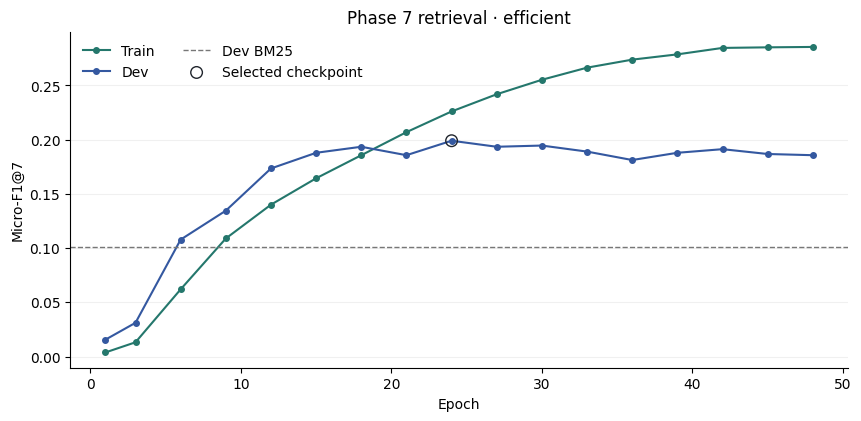

In [7]:
if RUN_MODE in ("train", "kd"):
    import matplotlib.pyplot as plt

    record = read_json(RUN_DIR / "metrics.json")
    records = pd.DataFrame([
        {"Epoch": row["epoch_position"],
         "Train F1@7": row["train"]["micro_f1_at_7"], "Dev F1@7": row["dev"]["micro_f1_at_7"],
         "Best Dev": row["best_dev_f1_at_7"]}
        for row in record["evaluations"]
    ])
    display(records.style.format({"Epoch": "{:.2f}", "Train F1@7": "{:.4f}", "Dev F1@7": "{:.4f}",
                                  "Best Dev": "{:.4f}"}).hide(axis="index"))
    if not records.empty:
        best = result["best"]
        fig, ax = plt.subplots(figsize=(8.5, 4.1), layout="constrained")
        ax.plot(records["Epoch"], records["Train F1@7"], color="#24776c", marker="o", ms=4, label="Train")
        ax.plot(records["Epoch"], records["Dev F1@7"], color="#3458a0", marker="o", ms=4, label="Dev")
        ax.axhline(data.bm25_metrics["dev"]["micro_f1_at_7"], ls="--", lw=1,
                   color="#777777", label="Dev BM25")
        ax.scatter(best["epoch_position"], best["dev"]["micro_f1_at_7"], s=70,
                   facecolors="none", edgecolors="#20252d", zorder=4, label="Selected checkpoint")
        ax.set(xlabel="Epoch", ylabel="Micro-F1@7", title=f"Phase 7 retrieval · {ARCHITECTURE}")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=.18)
        ax.legend(frameon=False, ncols=2)
        fig.savefig(RUN_DIR / "f1_history.png", dpi=160, bbox_inches="tight")
        plt.show()

## 8. Run artifacts and teacher handoff

Upload the `submission.zip` printed by the selected mode. The reranker writes under `cs781_phase7/reranked/` and stores a Dev comparison in `rerank_report.json`. The archive root contains `prediction.json`, which maps every test query ID to seven ranked candidate IDs.

Keep `best_model.pt`, `best_model.json` and `metrics.json` from the three larger runs. The tensor file stores the selected trainable EMA weights. To reconstruct a teacher, initialize the same Phase 1 checkpoint and retrieval architecture, then load the EMA tensors by parameter name using the metadata. Choose the teacher using completed Dev scores. Retain the gold student's metrics for comparison with its distilled counterpart.

To finish a Test export that ran out of active time, set `EXPORT_ONLY = True` and run again with the same inputs and recovery state. This mode runs inference in a separate pass.

In [8]:
if RUN_MODE in ("train", "kd"):
    best = result["best"]
    print(f"Selected epoch {best['epoch_position']:.2f} · "
          f"Train Micro-F1@7 {best['train']['micro_f1_at_7']:.4f} · "
          f"Dev Micro-F1@7 {best['dev']['micro_f1_at_7']:.4f}")
    print(f"Stop reason · {result['stop_reason']} | Active time · {result['active_minutes']:.1f} min")
    artifacts = {
        "submission.zip": "Upload-ready Test archive",
        "prediction.json": "Ranked Test candidate IDs",
        "best_model.pt": "Selected EMA weights",
        "best_model.json": "Checkpoint identity and reconstruction settings",
        "dev_prediction.json": "Selected checkpoint's Dev ranking",
        "metrics.json": "BM25 reference, epoch loss and paired checks",
        "f1_history.png": "Training and Dev F1 plot",
        "recovery/": "Latest recovery states and verification receipts",
    }
    display(pd.DataFrame([
        {"Artifact": name, "Contents": description, "Path": str(RUN_DIR / name)}
        for name, description in artifacts.items() if (RUN_DIR / name).exists()
    ]).style.hide(axis="index"))

Selected epoch 24.00 · Train Micro-F1@7 0.2260 · Dev Micro-F1@7 0.1990
Stop reason · dev_patience | Active time · 106.8 min


Artifact,Contents,Path
submission.zip,Upload-ready Test archive,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/submission.zip
prediction.json,Ranked Test candidate IDs,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/prediction.json
best_model.pt,Selected EMA weights,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/best_model.pt
best_model.json,Checkpoint identity and reconstruction settings,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/best_model.json
dev_prediction.json,Selected checkpoint's Dev ranking,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/dev_prediction.json
metrics.json,"BM25 reference, epoch loss and paired checks",/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/metrics.json
f1_history.png,Training and Dev F1 plot,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/f1_history.png
recovery/,Latest recovery states and verification receipts,/kaggle/working/cs781_phase7/runs/efficient_kd_encdec/recovery


## References and provenance

- CS781 Capstone §13, *Prior Case Retrieval*. Split-local candidate pools, submission schema and Micro-F1@7.
- Karpukhin et al. (2020), [Dense Passage Retrieval](https://aclanthology.org/2020.emnlp-main.550/).
- Liu et al. (2022), [IA³](https://arxiv.org/abs/2205.05638).
- The user's Phase 1 legal models and Phase 7 preparation notebook. Input and source identities are recorded with each run.
- [Official CS781 dataset](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone)